In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_excel("C:/Users/aksha/Desktop/project/premiums (2).xlsx")

In [3]:
df

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,24,Female,Northwest,Unmarried,0,Underweight,No Smoking,Self-Employed,25L - 40L,35,No Disease,Bronze,9111
49996,47,Female,Southeast,Married,2,Normal,No Smoking,Salaried,> 40L,82,Thyroid,Gold,27076
49997,21,Male,Northwest,Unmarried,0,Normal,Regular,Freelancer,25L - 40L,32,No Disease,Bronze,8564
49998,18,Male,Northwest,Unmarried,2,Normal,No Smoking,Salaried,10L - 25L,20,No Disease,Bronze,9490


In [4]:
df.shape

(50000, 13)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Age                    50000 non-null  int64
 1   Gender                 50000 non-null  str  
 2   Region                 50000 non-null  str  
 3   Marital_status         50000 non-null  str  
 4   Number Of Dependants   50000 non-null  int64
 5   BMI_Category           50000 non-null  str  
 6   Smoking_Status         49989 non-null  str  
 7   Employment_Status      49998 non-null  str  
 8   Income_Level           49987 non-null  str  
 9   Income_Lakhs           50000 non-null  int64
 10  Medical History        50000 non-null  str  
 11  Insurance_Plan         50000 non-null  str  
 12  Annual_Premium_Amount  50000 non-null  int64
dtypes: int64(4), str(9)
memory usage: 8.5 MB


In [6]:
df.isnull().sum()

Age                       0
Gender                    0
Region                    0
Marital_status            0
Number Of Dependants      0
BMI_Category              0
Smoking_Status           11
Employment_Status         2
Income_Level             13
Income_Lakhs              0
Medical History           0
Insurance_Plan            0
Annual_Premium_Amount     0
dtype: int64

In [7]:
df=df.fillna({'Smoking_Status':df["Smoking_Status"].mode()[0],'Income_Level':df.Income_Level.mode()[0],'Employment_Status':df.Employment_Status.mode()[0]},inplace=True)

In [8]:
df.isnull().sum()

Age                      0
Gender                   0
Region                   0
Marital_status           0
Number Of Dependants     0
BMI_Category             0
Smoking_Status           0
Employment_Status        0
Income_Level             0
Income_Lakhs             0
Medical History          0
Insurance_Plan           0
Annual_Premium_Amount    0
dtype: int64

In [9]:
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,34.593480,1.712080,23.018200,15768.116320
std,15.000437,1.498248,24.219197,8419.839675
min,18.000000,-3.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8608.000000
50%,31.000000,2.000000,17.000000,13929.000000
75%,45.000000,3.000000,31.000000,22275.250000
max,356.000000,5.000000,930.000000,43471.000000


In [10]:
df['Number Of Dependants']=df['Number Of Dependants'].abs()

In [11]:
df.describe()

,Age,Number Of Dependants,Income_Lakhs,Annual_Premium_Amount
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,34.593480,1.717520,23.018200,15768.116320
std,15.000437,1.492009,24.219197,8419.839675
min,18.000000,0.000000,1.000000,3501.000000
25%,22.000000,0.000000,7.000000,8608.000000
50%,31.000000,2.000000,17.000000,13929.000000
75%,45.000000,3.000000,31.000000,22275.250000
max,356.000000,5.000000,930.000000,43471.000000


In [12]:
num_col=df.select_dtypes(include=['float64','int64']).columns
num_col

Index(['Age', 'Number Of Dependants', 'Income_Lakhs', 'Annual_Premium_Amount'], dtype='str')

In [13]:
import seaborn as sns

In [14]:
import matplotlib.pyplot as plt

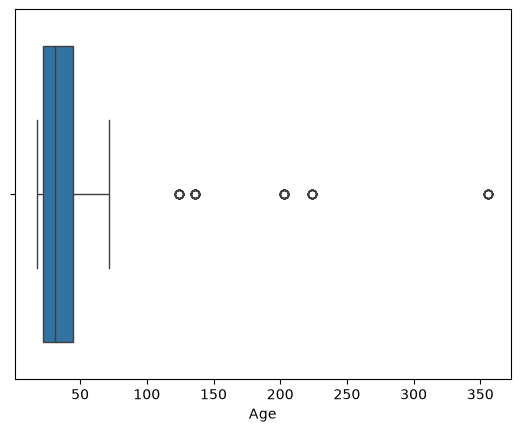

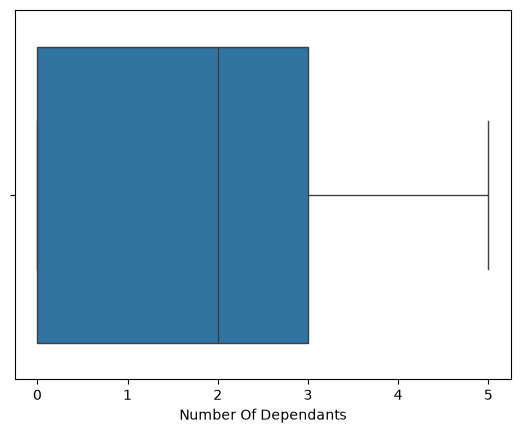

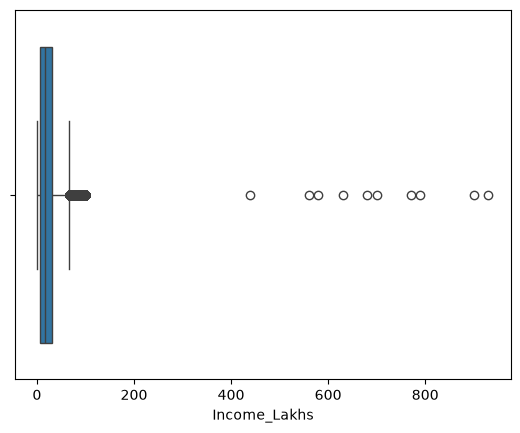

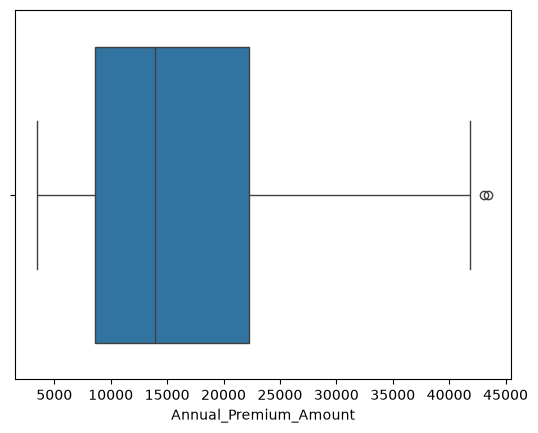

In [15]:
for col in num_col:
    sns.boxplot(x=df[col])
    plt.show()

In [16]:
df[df['Age']>100]['Age'].unique()

array([224, 124, 136, 203, 356])

In [17]:
df1=df[df.Age<=100]

In [18]:
df1.Age.describe()

count    49942.000000
mean        34.403648
std         13.682354
min         18.000000
25%         22.000000
50%         31.000000
75%         45.000000
max         72.000000
Name: Age, dtype: float64

In [19]:
def get_iqr_bounds(col):
    Q1, Q3 = col.quantile([0.25, 0.75])
    IQR = Q3-Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return lower_bound, upper_bound

lower, upper = get_iqr_bounds(df1['Income_Lakhs'])
lower, upper

(-29.0, 67.0)

In [20]:
df1[df1.Income_Lakhs>upper].shape

(3560, 13)

In [21]:
quantile_thresold = df1.Income_Lakhs.quantile(0.999)
quantile_thresold

np.float64(100.0)

In [22]:
df1[df1.Income_Lakhs>quantile_thresold].shape

(10, 13)

In [23]:
df2 = df1[df1.Income_Lakhs<=quantile_thresold].copy()
df2.shape

(49932, 13)

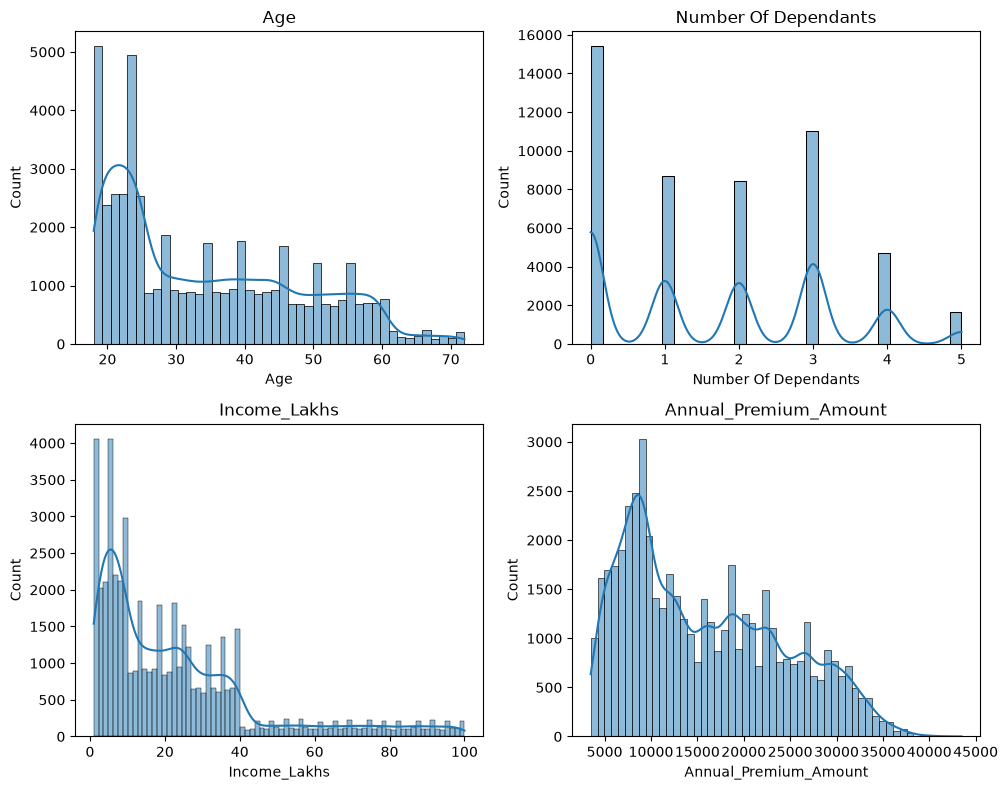

In [24]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))
for i, column in enumerate(num_col):
    ax = axs[i//2, i%2]
    sns.histplot(df2[column], kde=True, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

In [25]:
df.head(3)

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164


In [26]:
categorical_cols=['Gender','Region','Marital_status','BMI_Category','Smoking_Status','Employment_Status','Income_Level','Medical History','Insurance_Plan']
for col in categorical_cols:
    print(col,":",df2[col].unique())

Gender : <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
Region : <ArrowStringArray>
['Northwest', 'Southeast', 'Northeast', 'Southwest']
Length: 4, dtype: str
Marital_status : <ArrowStringArray>
['Unmarried', 'Married']
Length: 2, dtype: str
BMI_Category : <ArrowStringArray>
['Normal', 'Obesity', 'Overweight', 'Underweight']
Length: 4, dtype: str
Smoking_Status : <ArrowStringArray>
[    'No Smoking',        'Regular',     'Occasional',      'Smoking=0',
 'Does Not Smoke',    'Not Smoking']
Length: 6, dtype: str
Employment_Status : <ArrowStringArray>
['Salaried', 'Self-Employed', 'Freelancer']
Length: 3, dtype: str
Income_Level : <ArrowStringArray>
['<10L', '10L - 25L', '> 40L', '25L - 40L']
Length: 4, dtype: str
Medical History : <ArrowStringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart d

In [27]:
df2['Smoking_Status']=df2['Smoking_Status'].replace({
    'Not Smoking': 'No Smoking',
    'Does Not Smoke': 'No Smoking',
    'Smoking=0': 'No Smoking'
})



In [28]:
df2.head()

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365


In [29]:
df2['Smoking_Status'].unique()

<ArrowStringArray>
['No Smoking', 'Regular', 'Occasional']
Length: 3, dtype: str

In [30]:
df2.head(3)

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164


In [31]:
pct_count = df2['Gender'].value_counts(normalize=True)*100
pct_count

Gender
Male      54.960747
Female    45.039253
Name: proportion, dtype: float64

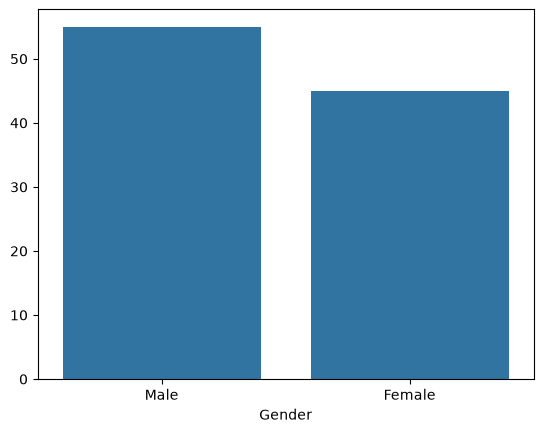

In [32]:
sns.barplot(x=pct_count.index, y=pct_count.values)
plt.show()

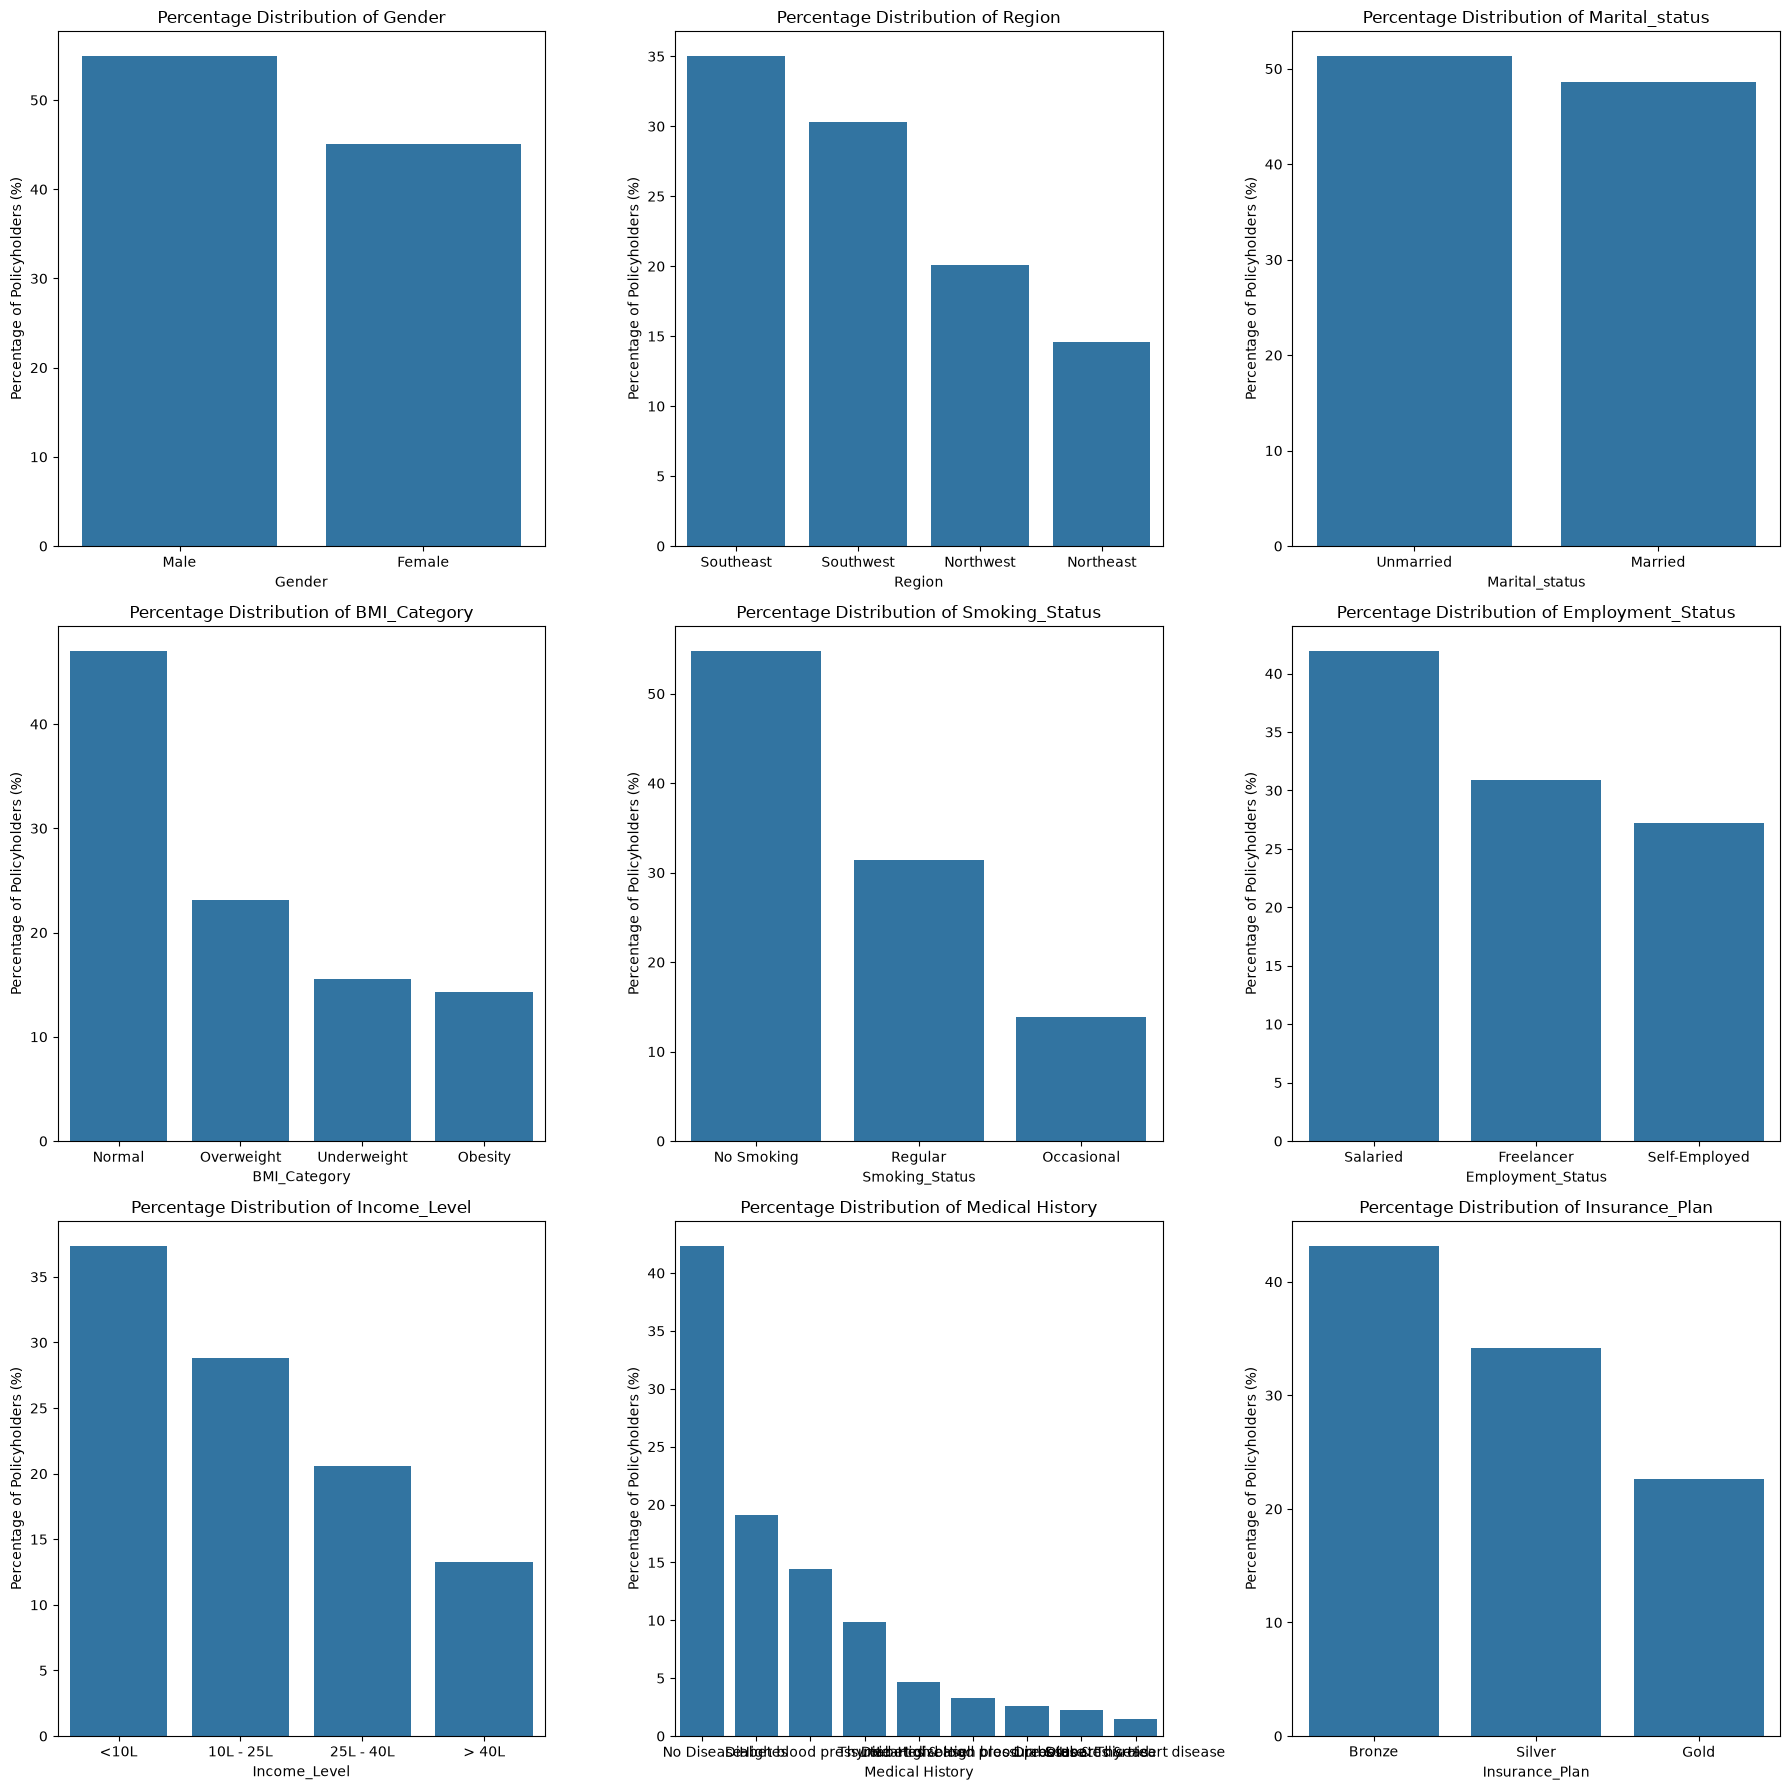

In [33]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
axes = axes.flatten()

for ax, column in zip(axes, categorical_cols):
    category_counts = df2[column].value_counts(normalize=True) * 100
    
    sns.barplot(x=category_counts.index, y=category_counts.values, ax=ax)
    ax.set_title(f'Percentage Distribution of {column}')
    ax.set_ylabel('Percentage of Policyholders (%)')
    ax.set_xlabel(column) 

plt.tight_layout() 
plt.show()

Insurance_Plan  Bronze  Gold  Silver
Income_Level                        
10L - 25L         5308  3880    5183
25L - 40L         3683  2845    3750
<10L             12229   931    5498
> 40L              329  3654    2642


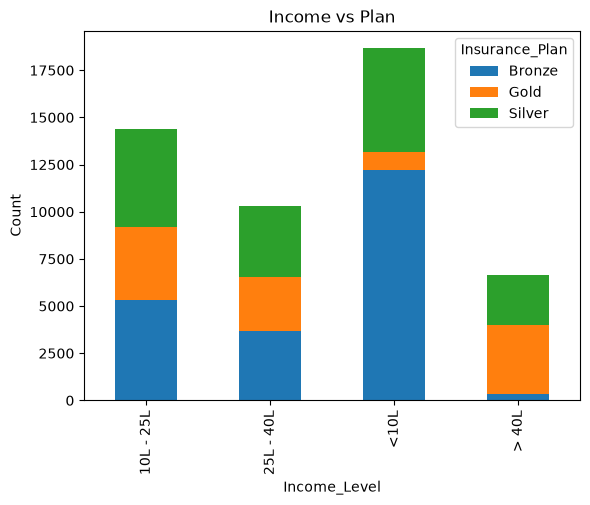

In [34]:
crosstab = pd.crosstab(df2['Income_Level'], df2['Insurance_Plan'])
print(crosstab)

crosstab.plot(kind='bar', stacked=True)
plt.title('Income vs Plan')
plt.ylabel('Count')
plt.show()

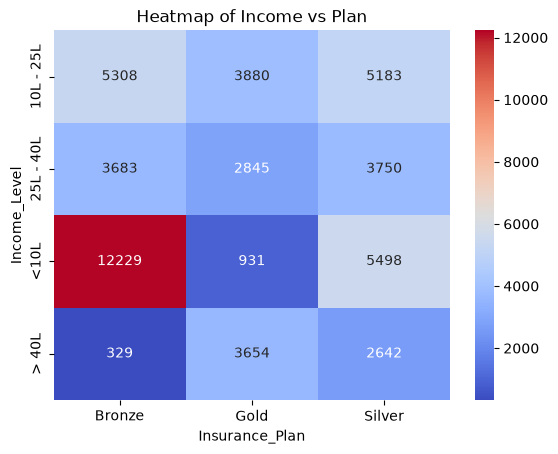

In [35]:
sns.heatmap(crosstab, annot=True, cmap='coolwarm',fmt="d")
plt.title('Heatmap of Income vs Plan')
plt.show()

In [36]:
df2.columns = df.columns.str.replace(" ","_").str.lower()
df2.head(5)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,18,Male,Northeast,Unmarried,0,Overweight,Regular,Self-Employed,> 40L,99,High blood pressure,Silver,13365


In [37]:
risk_scores = {
    "diabetes": 6,
    "heart disease": 8,
    "high blood pressure":6,
    "thyroid": 5,
    "no disease": 0,
    "none":0
}
df2[['disease1', 'disease2']] = df2['medical_history'].str.split(" & ", expand=True).apply(lambda x: x.str.lower())
df2['disease1'].fillna('none', inplace=True)
df2['disease2'].fillna('none', inplace=True)
df2['total_risk_score'] = 0
for disease in ['disease1', 'disease2']:
    df2['total_risk_score'] += df2[disease].map(risk_scores)
max_score = df2['total_risk_score'].max()
min_score = df2['total_risk_score'].min()
df2['normalized_risk_score'] = (df2['total_risk_score'] - min_score) / (max_score - min_score)
df2.head(2)

C:\Users\aksha\AppData\Local\Temp\ipykernel_18700\3385490679.py:10: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df2['disease1'].fillna('none', inplace=True)
C:\Users\aksha\AppData\Local\Temp\ipykernel_18700\3385490679.py:11: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment u

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,disease1,disease2,total_risk_score,normalized_risk_score
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053,diabetes,NaN,NaN,NaN
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339,diabetes,NaN,NaN,NaN


In [38]:
df2['insurance_plan'] = df2['insurance_plan'].map({'Bronze': 1, 'Silver': 2, 'Gold': 3})

In [39]:
df2.income_level.unique()

<ArrowStringArray>
['<10L', '10L - 25L', '> 40L', '25L - 40L']
Length: 4, dtype: str

In [40]:
df2['income_level'] = df2['income_level'].map({'<10L':1, '10L - 25L': 2, '25L - 40L':3, '> 40L':4})

In [41]:
nominal_cols = ['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status', 'employment_status']
df3 = pd.get_dummies(df2, columns=nominal_cols, drop_first=True, dtype=int)
df3.head(3)

,age,number_of_dependants,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,disease1,disease2,total_risk_score,...,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,Diabetes,1,9053,diabetes,NaN,NaN,...,0,0,1,0,0,0,0,0,1,0
1,29,2,1,6,Diabetes,1,16339,diabetes,NaN,NaN,...,1,0,0,1,0,0,0,1,1,0
2,49,2,2,20,High blood pressure,2,18164,high blood pressure,NaN,NaN,...,0,0,0,0,0,0,0,0,0,1


In [42]:
df3.info()

<class 'pandas.DataFrame'>
Index: 49932 entries, 0 to 49999
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              49932 non-null  int64  
 1   number_of_dependants             49932 non-null  int64  
 2   income_level                     49932 non-null  int64  
 3   income_lakhs                     49932 non-null  int64  
 4   medical_history                  49932 non-null  str    
 5   insurance_plan                   49932 non-null  int64  
 6   annual_premium_amount            49932 non-null  int64  
 7   disease1                         49932 non-null  str    
 8   disease2                         4771 non-null   str    
 9   total_risk_score                 4771 non-null   float64
 10  normalized_risk_score            4771 non-null   float64
 11  gender_Male                      49932 non-null  int64  
 12  region_Northwest                 4

In [43]:
df4 = df3.drop(['medical_history','disease1', 'disease2', 'total_risk_score'], axis=1)
df4.head(3)                

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,1,9053,NaN,1,1,0,0,1,0,0,0,0,0,1,0
1,29,2,1,6,1,16339,NaN,0,0,1,0,0,1,0,0,0,1,1,0
2,49,2,2,20,2,18164,NaN,0,0,0,0,0,0,0,0,0,0,0,1


In [44]:
df4.columns

Index(['age', 'number_of_dependants', 'income_level', 'income_lakhs',
       'insurance_plan', 'annual_premium_amount', 'normalized_risk_score',
       'gender_Male', 'region_Northwest', 'region_Southeast',
       'region_Southwest', 'marital_status_Unmarried', 'bmi_category_Obesity',
       'bmi_category_Overweight', 'bmi_category_Underweight',
       'smoking_status_Occasional', 'smoking_status_Regular',
       'employment_status_Salaried', 'employment_status_Self-Employed'],
      dtype='str')

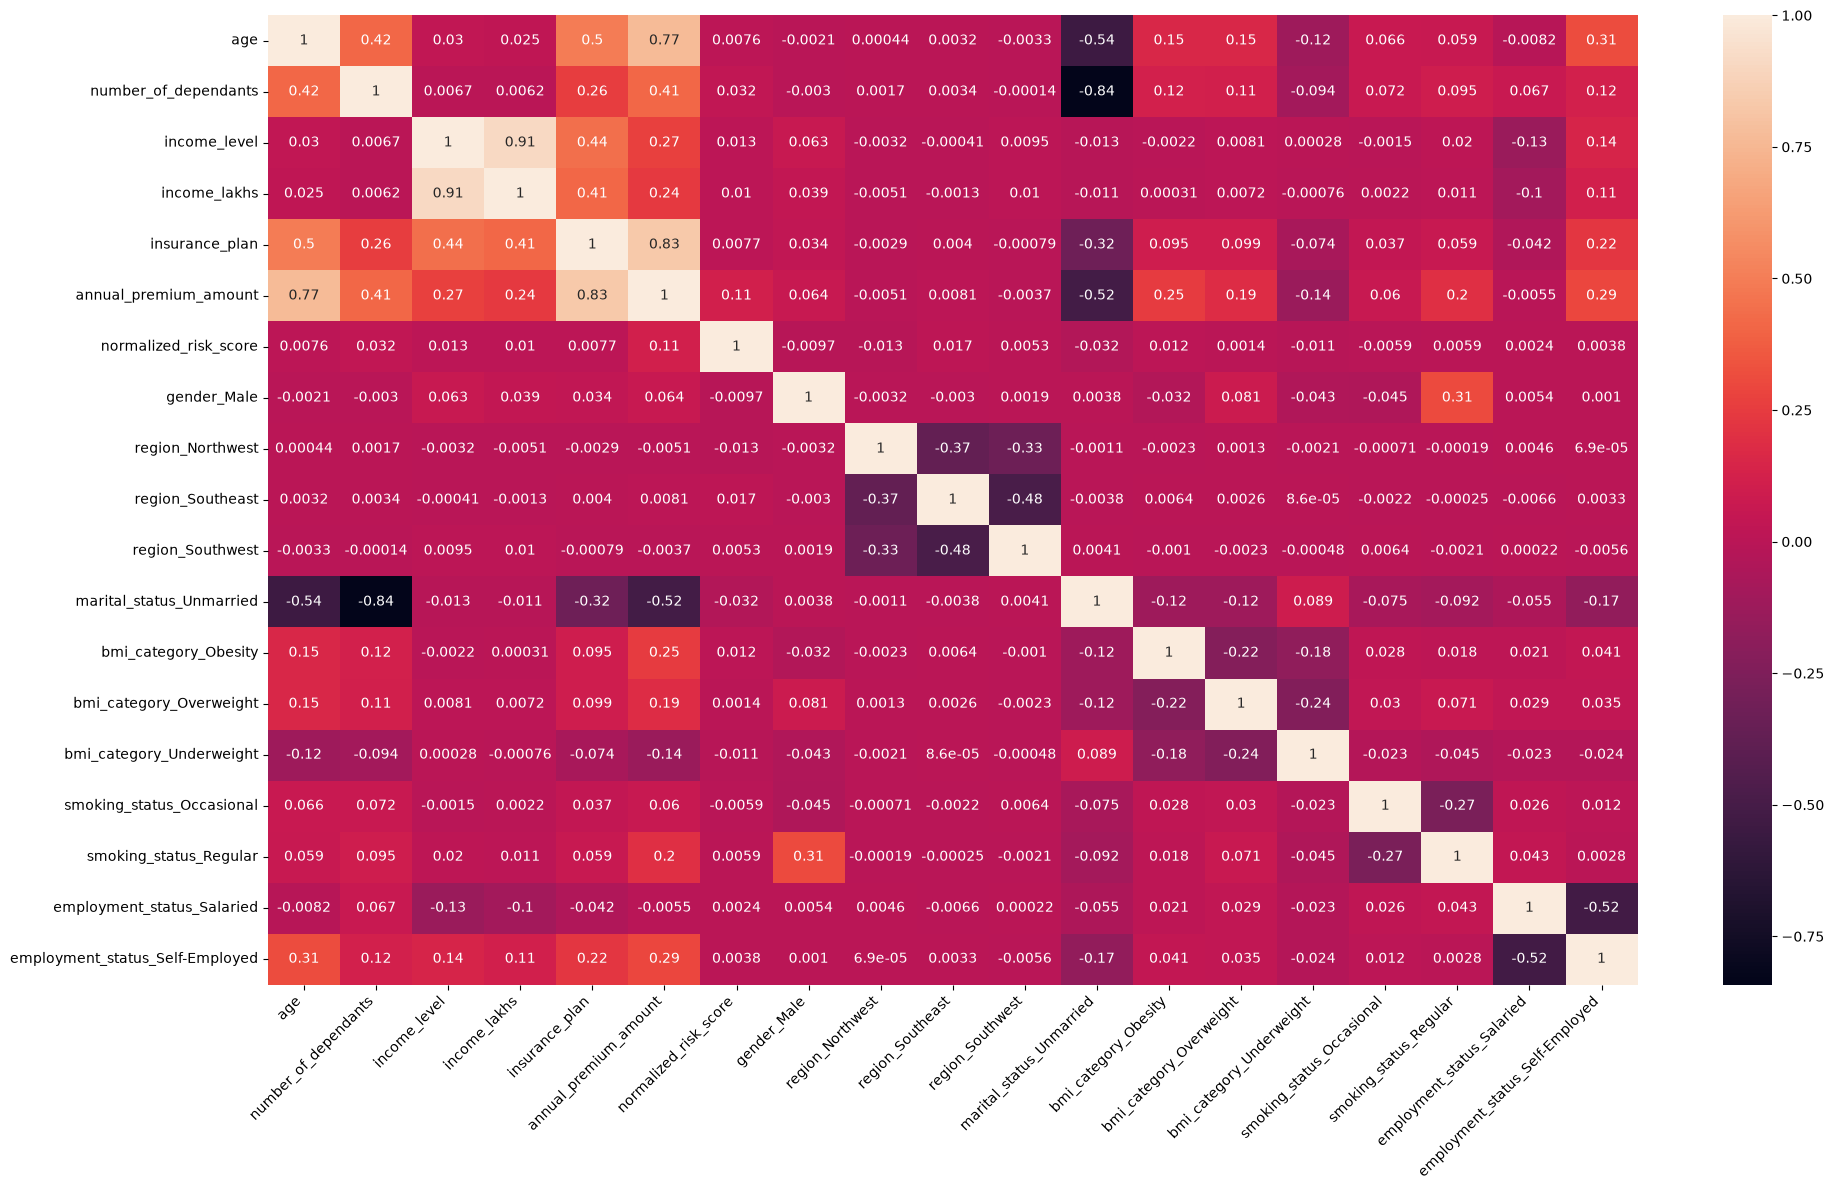

In [45]:
cm = df4.corr()

plt.figure(figsize=(20,12))
sns.heatmap(cm, annot=True)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [46]:
X = df4.drop('annual_premium_amount', axis='columns')
y = df4['annual_premium_amount']

from sklearn.preprocessing import MinMaxScaler

cols_to_scale = ['age','number_of_dependants', 'income_level',  'income_lakhs', 'insurance_plan']
scaler = MinMaxScaler()

X[cols_to_scale] = scaler.fit_transform(X[cols_to_scale])
X.describe()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
count,49932.000000,49932.000000,49932.000000,49932.000000,49932.000000,4771.000000,49932.000000,49932.000000,49932.000000,49932.000000,49932.000000,49932.000000,49932.000000,49932.000000,49932.000000,49932.000000,49932.000000,49932.00000
mean,0.303766,0.343575,0.365844,0.221081,0.397471,0.536994,0.549607,0.200853,0.350336,0.303132,0.513478,0.143175,0.231194,0.155391,0.138288,0.313767,0.419430,0.27205
std,0.253377,0.298418,0.349720,0.223928,0.392440,0.415010,0.497538,0.400642,0.477080,0.459616,0.499823,0.350254,0.421601,0.362281,0.345206,0.464027,0.493471,0.44502
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,0.074074,0.000000,0.000000,0.060606,0.000000,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,0.240741,0.400000,0.333333,0.161616,0.500000,0.333333,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,0.500000,0.600000,0.666667,0.303030,0.500000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.00000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [47]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Column'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values,i) for i in range(data.shape[1])]
    return vif_df

In [48]:
print(X.nunique())

age                                 55
number_of_dependants                 6
income_level                         4
income_lakhs                       100
insurance_plan                       3
normalized_risk_score                3
gender_Male                          2
region_Northwest                     2
region_Southeast                     2
region_Southwest                     2
marital_status_Unmarried             2
bmi_category_Obesity                 2
bmi_category_Overweight              2
bmi_category_Underweight             2
smoking_status_Occasional            2
smoking_status_Regular               2
employment_status_Salaried           2
employment_status_Self-Employed      2
dtype: int64


In [49]:
print(X.isnull().sum())

age                                    0
number_of_dependants                   0
income_level                           0
income_lakhs                           0
insurance_plan                         0
normalized_risk_score              45161
gender_Male                            0
region_Northwest                       0
region_Southeast                       0
region_Southwest                       0
marital_status_Unmarried               0
bmi_category_Obesity                   0
bmi_category_Overweight                0
bmi_category_Underweight               0
smoking_status_Occasional              0
smoking_status_Regular                 0
employment_status_Salaried             0
employment_status_Self-Employed        0
dtype: int64


In [50]:
X['normalized_risk_score']=X['normalized_risk_score'].fillna(X['normalized_risk_score'].median())

In [51]:
print(X.isnull().sum())

age                                0
number_of_dependants               0
income_level                       0
income_lakhs                       0
insurance_plan                     0
normalized_risk_score              0
gender_Male                        0
region_Northwest                   0
region_Southeast                   0
region_Southwest                   0
marital_status_Unmarried           0
bmi_category_Obesity               0
bmi_category_Overweight            0
bmi_category_Underweight           0
smoking_status_Occasional          0
smoking_status_Regular             0
employment_status_Salaried         0
employment_status_Self-Employed    0
dtype: int64


In [52]:
calculate_vif(X)

,Column,VIF
0,age,1.941647
1,number_of_dependants,3.485621
2,income_level,5.962128
3,income_lakhs,5.665431
4,insurance_plan,1.767718
5,normalized_risk_score,1.003945
6,gender_Male,1.118111
7,region_Northwest,1.901354
8,region_Southeast,2.212665
9,region_Southwest,2.147800


In [53]:
x_reduced=X.drop('income_level', axis="columns")

In [54]:
calculate_vif(x_reduced)

,Column,VIF
0,age,1.928326
1,number_of_dependants,3.485539
2,income_lakhs,1.282415
3,insurance_plan,1.698830
4,normalized_risk_score,1.003881
5,gender_Male,1.114179
6,region_Northwest,1.901214
7,region_Southeast,2.212555
8,region_Southwest,2.147675
9,marital_status_Unmarried,4.074612


In [55]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split

X_train, X_test, y_train, y_test = train_test_split(x_reduced, y, test_size=0.30, random_state=10)
print("x train: ",X_train.shape)
print("x test: ",X_test.shape)
print("y train: ",y_train.shape)
print("y test: ",y_test.shape)

x train:  (34952, 17)
x test:  (14980, 17)
y train:  (34952,)
y test:  (14980,)


In [56]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
test_score = model_lr.score(X_test, y_test)
train_score = model_lr.score(X_train, y_train)
train_score, test_score

(0.9127311286348202, 0.9109575640401832)

In [57]:
y_pred = model_lr.predict(X_test)

mse_lr = mean_squared_error(y_test, y_pred)
rmse_lr = np.sqrt(mse_lr)
print("Linear Regression ==> MSE: ", mse_lr, "RMSE: ", rmse_lr)

Linear Regression ==> MSE:  6274999.13606219 RMSE:  2504.9948375320437


In [58]:
X_test.shape

(14980, 17)

In [59]:
np.set_printoptions(suppress=True, precision=6)
model_lr.coef_

array([12739.877199,  -279.006683,  -469.057317, 12657.831583,
        3865.731972,    95.719245,   -60.552636,    25.082663,
         -10.051924, -1349.149039,  3439.058707,  1714.075851,
         313.287353,   866.718735,  2408.302841,   317.686837,
         461.914615])

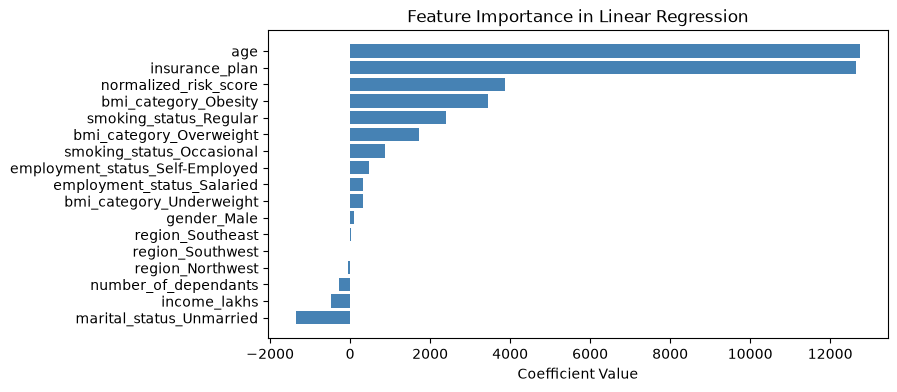

In [60]:
feature_importance = model_lr.coef_
coef_df = pd.DataFrame(feature_importance, index=X_train.columns, columns=['Coefficients'])
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Linear Regression')
plt.show()

In [61]:
model_rg = Ridge(alpha=1)
model_rg.fit(X_train, y_train)
test_score = model_rg.score(X_test, y_test)
train_score = model_rg.score(X_train, y_train)
train_score, test_score

(0.9127310746876834, 0.9109589371803554)

In [62]:
y_pred = model_rg.predict(X_test)

mse_lr = mean_squared_error(y_test, y_pred)
rmse_lr = np.sqrt(mse_lr)
print("Ridge Regression ==> MSE: ", mse_lr, "RMSE: ", rmse_lr)

Ridge Regression ==> MSE:  6274902.368118897 RMSE:  2504.9755224590313


In [63]:
from xgboost import XGBRegressor

In [64]:
model_xgb = XGBRegressor(n_estimators=20, max_depth=3)
model_xgb.fit(X_train, y_train)
model_xgb.score(X_test, y_test)

0.9636289477348328

In [65]:
y_pred = model_xgb.predict(X_test)

mse_lr = mean_squared_error(y_test, y_pred)
rmse_lr = np.sqrt(mse_lr)
print("XGBoost Regression ==> MSE: ", mse_lr, "RMSE: ", rmse_lr)

XGBoost Regression ==> MSE:  2563139.5 RMSE:  1600.9807931390058


In [66]:
model_xgb = XGBRegressor()
param_grid = {
    'n_estimators': [20, 40, 50],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5],
}
random_search = RandomizedSearchCV(model_xgb, param_grid, n_iter=10, cv=3, scoring='r2', random_state=42, n_jobs=-1)
random_search.fit(X_train, y_train)
random_search.best_score_

np.float64(0.9651340842247009)

In [67]:
random_search.best_params_

{'n_estimators': 50, 'max_depth': 5, 'learning_rate': 0.1}

In [68]:
best_model = random_search.best_estimator_

In [69]:
feature_importance = best_model.feature_importances_


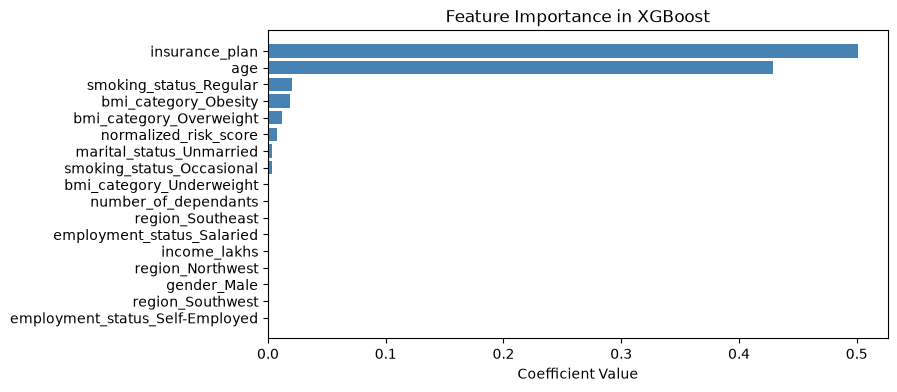

In [70]:
coef_df = pd.DataFrame(feature_importance, index=X_train.columns, columns=['Coefficients'])
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in XGBoost')
plt.show()

In [71]:
y_pred = best_model.predict(X_test)

residuals = y_pred - y_test
residuals_pct = (residuals / y_test) * 100

results_df = pd.DataFrame({
    'actual': y_test, 
    'predicted': y_pred, 
    'diff': residuals, 
    'diff_pct': residuals_pct
})
results_df.head()

,actual,predicted,diff,diff_pct
7167,28672,28654.281250,-17.718750,-0.061798
14503,13400,13171.733398,-228.266602,-1.703482
43991,8892,6723.450684,-2168.549316,-24.387644
47910,29595,30007.441406,412.441406,1.393619
12861,18734,19016.937500,282.937500,1.510289


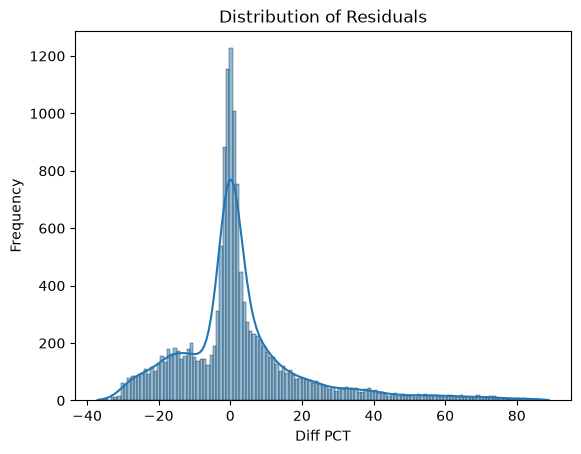

In [72]:
sns.histplot(results_df['diff_pct'], kde=True)
plt.title('Distribution of Residuals')
plt.xlabel('Diff PCT')
plt.ylabel('Frequency')
plt.show()

In [73]:
X_test.shape

(14980, 17)

In [74]:
extreme_error_threshold = 10
extreme_results_df = results_df[np.abs(results_df['diff_pct']) > extreme_error_threshold]
extreme_results_df.head()

,actual,predicted,diff,diff_pct
43991,8892,6723.450684,-2168.549316,-24.387644
33892,8642,7471.460938,-1170.539062,-13.544770
32115,8643,7211.654785,-1431.345215,-16.560745
41992,5260,6575.430664,1315.430664,25.008188
9393,9299,7230.064453,-2068.935547,-22.249011


In [75]:
extreme_results_df.shape

(5943, 4)

In [76]:
extreme_errors_pct = extreme_results_df.shape[0]*100/X_test.shape[0]
extreme_errors_pct

39.67289719626168

In [77]:
extreme_results_df[abs(extreme_results_df.diff_pct)>50].sort_values("diff_pct",ascending=False)

,actual,predicted,diff,diff_pct
29904,3503,6616.772949,3113.772949,88.888751
18922,3502,6610.511719,3108.511719,88.763898
42789,3508,6610.511719,3102.511719,88.441041
18094,3505,6575.430664,3070.430664,87.601445
47573,3531,6616.772949,3085.772949,87.390908
...,...,...,...,...
49595,4379,6581.691895,2202.691895,50.301254
20117,5095,7653.543945,2558.543945,50.216760
11461,4401,6610.511719,2209.511719,50.204765
7948,4418,6633.235840,2215.235840,50.141146


In [78]:
extreme_errors_df = X_test.loc[extreme_results_df.index]
extreme_errors_df.head(2)

,age,number_of_dependants,income_lakhs,insurance_plan,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
43991,0.129630,0.6,0.070707,0.0,0.333333,0,0,1,0,0,0,0,1,0,0,1,0
33892,0.111111,0.4,0.303030,0.0,0.333333,1,1,0,0,1,0,1,0,0,1,1,0


In [79]:
extreme_errors_df = X_test.loc[extreme_results_df.index]
extreme_errors_df.head(2)

,age,number_of_dependants,income_lakhs,insurance_plan,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
43991,0.129630,0.6,0.070707,0.0,0.333333,0,0,1,0,0,0,0,1,0,0,1,0
33892,0.111111,0.4,0.303030,0.0,0.333333,1,1,0,0,1,0,1,0,0,1,1,0


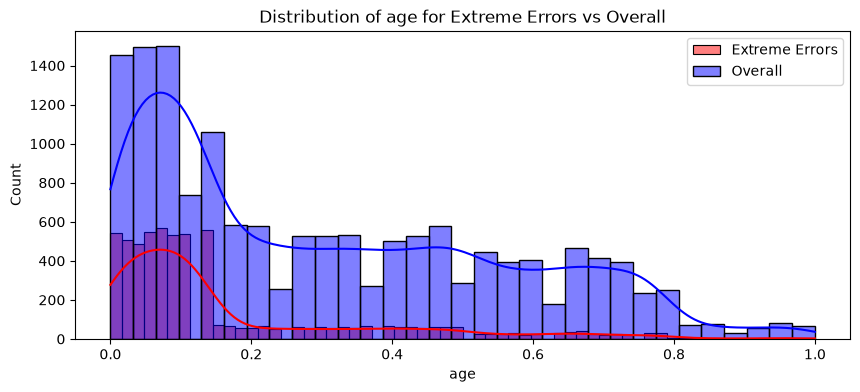

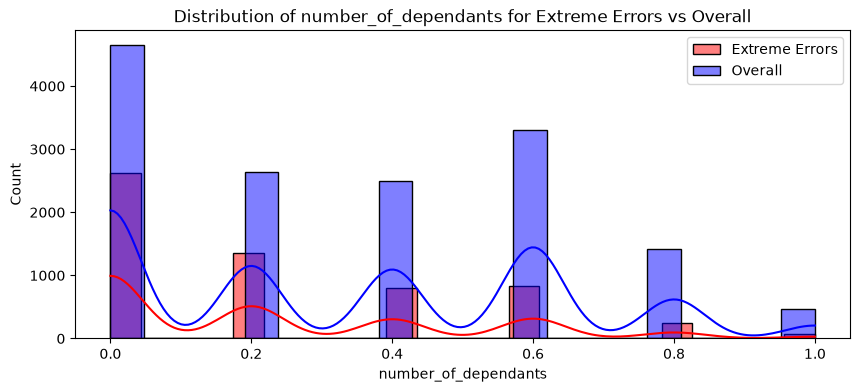

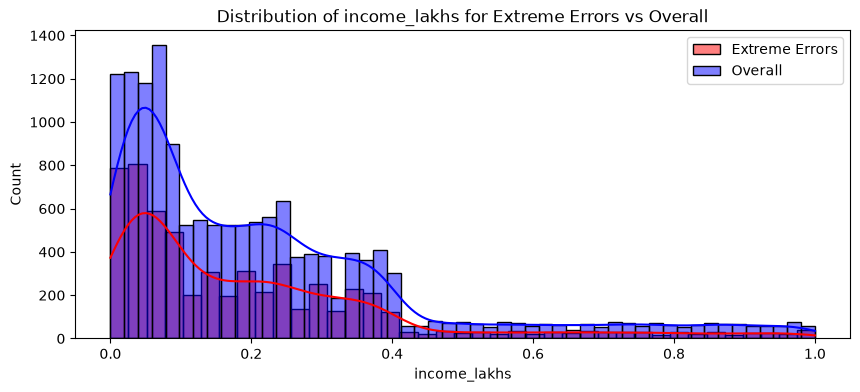

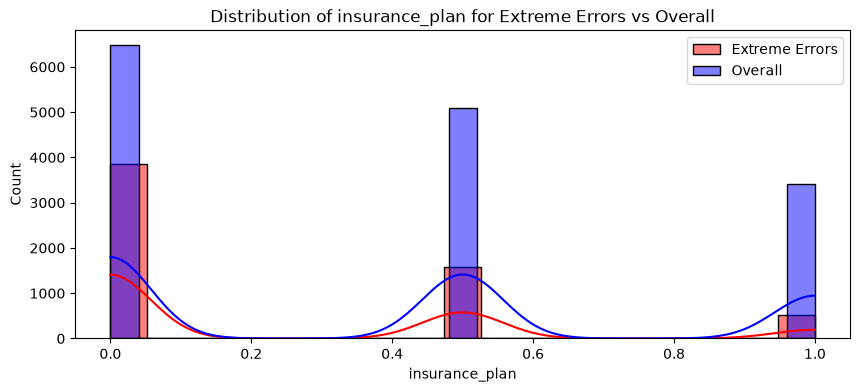

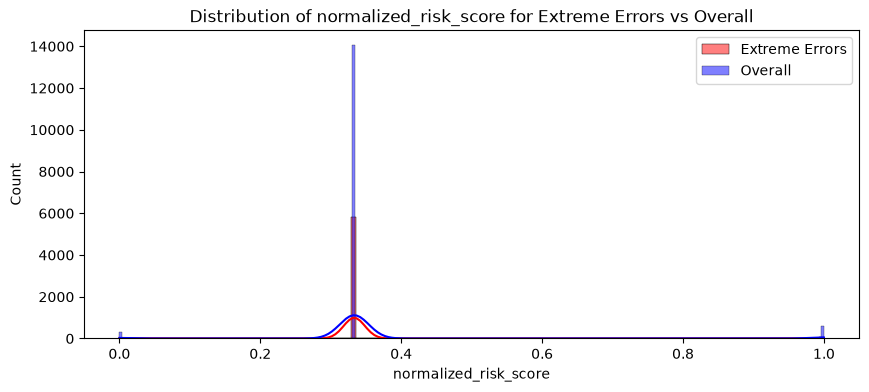

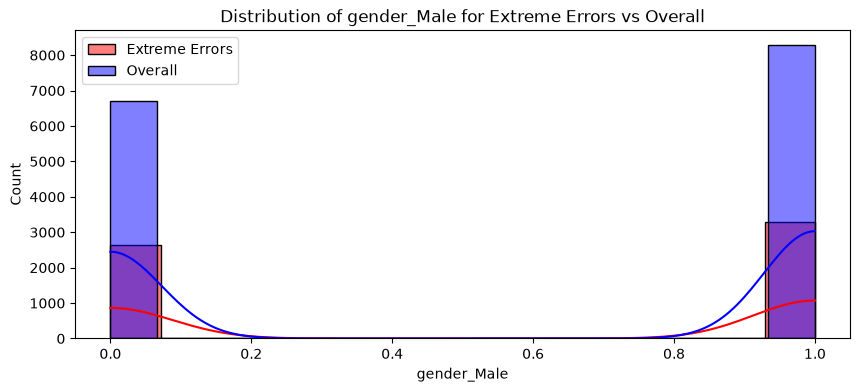

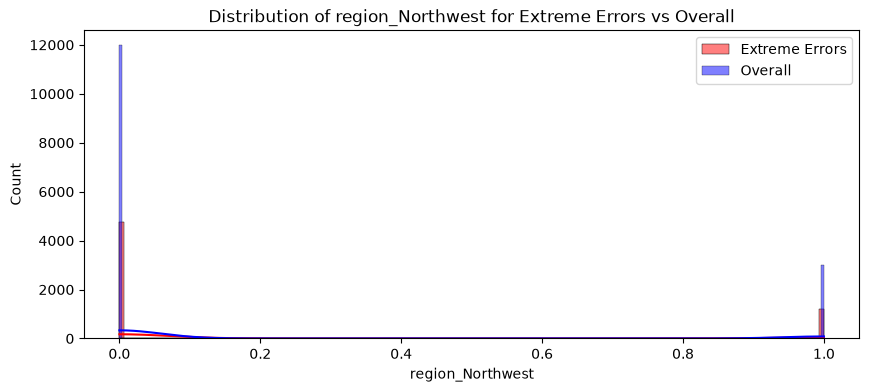

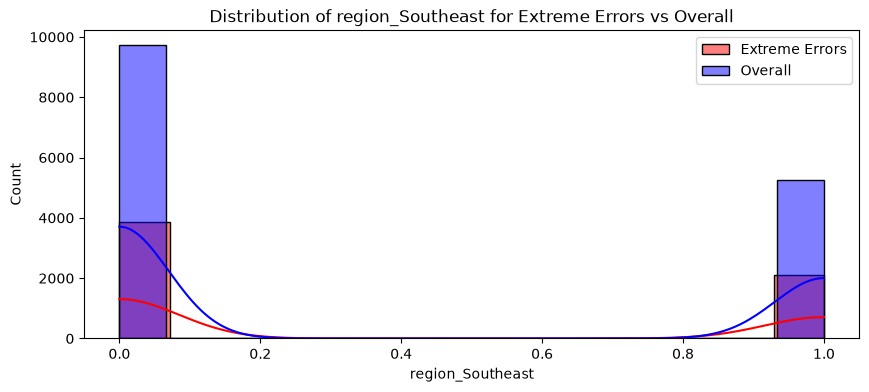

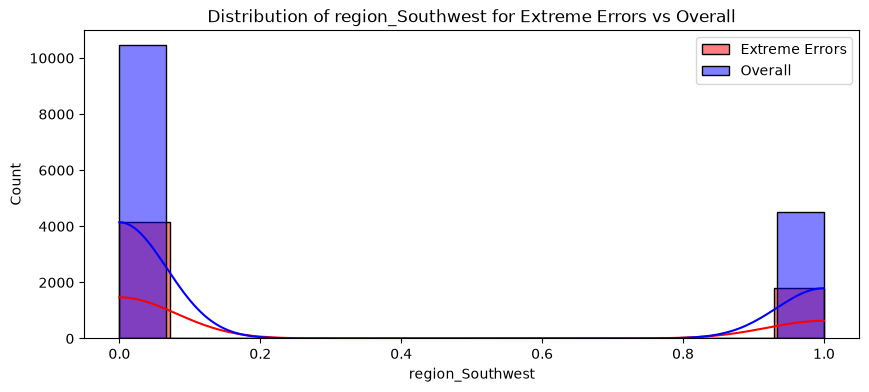

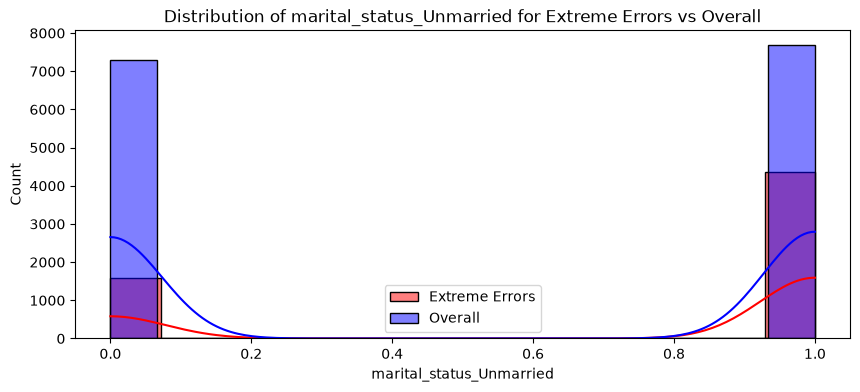

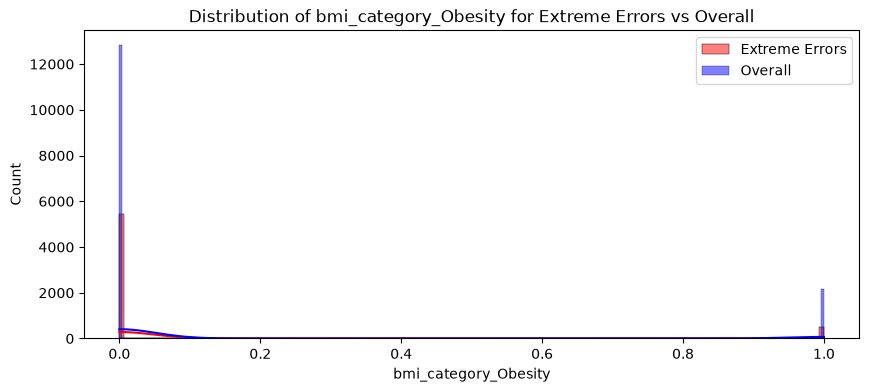

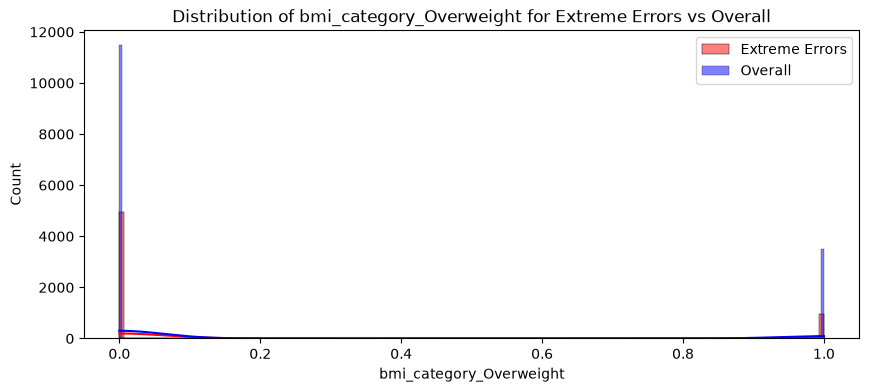

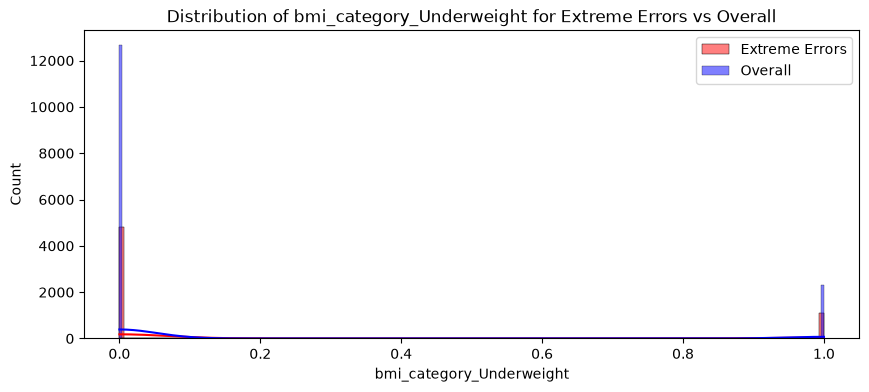

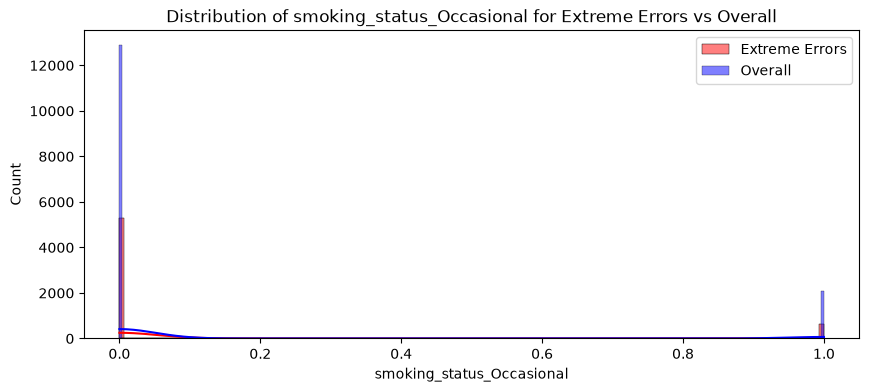

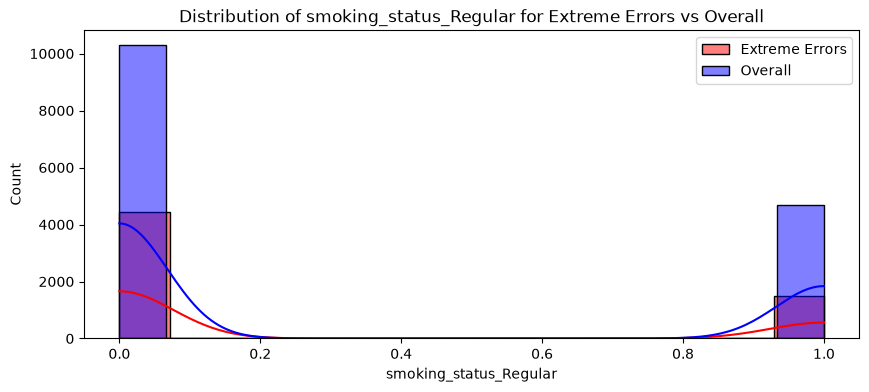

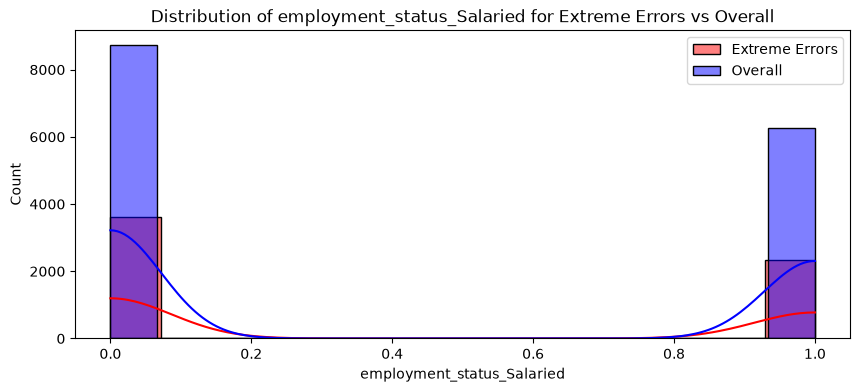

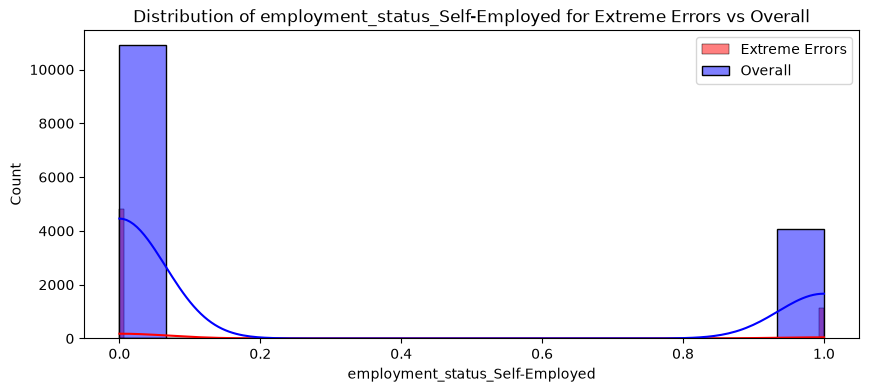

In [80]:
for feature in X_test.columns:
    plt.figure(figsize=(10, 4))
    sns.histplot(extreme_errors_df[feature], color='red', label='Extreme Errors', kde=True)
    sns.histplot(X_test[feature], color='blue', label='Overall', alpha=0.5, kde=True)
    plt.legend()
    plt.title(f'Distribution of {feature} for Extreme Errors vs Overall')
    plt.show()

In [81]:
extreme_errors_df['income_level']=-1

In [82]:
df_reversed = pd.DataFrame()
df_reversed[cols_to_scale] = scaler.inverse_transform(extreme_errors_df[cols_to_scale])
df_reversed.head()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan
0,25.0,3.0,-2.0,8.0,1.0
1,24.0,2.0,-2.0,31.0,1.0
2,24.0,2.0,-2.0,23.0,1.0
3,21.0,1.0,-2.0,23.0,1.0
4,18.0,3.0,-2.0,32.0,1.0


In [83]:
df_reversed.describe()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan
count,5943.000000,5943.000000,5943.0,5943.000000,5943.000000
mean,26.870436,1.152112,-2.0,20.949520,1.441528
std,10.319241,1.303911,0.0,20.743066,0.650897
min,18.000000,0.000000,-2.0,1.000000,1.000000
25%,20.000000,0.000000,-2.0,6.000000,1.000000
50%,23.000000,1.000000,-2.0,14.000000,1.000000
75%,28.000000,2.000000,-2.0,29.000000,2.000000
max,72.000000,5.000000,-2.0,100.000000,3.000000


<Axes: xlabel='age', ylabel='Count'>

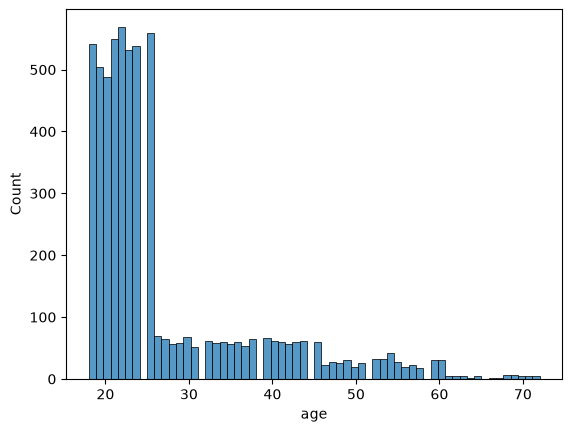

In [84]:
sns.histplot(df_reversed.age)